In [22]:
# =================================================
# Day 9: Acuity vs. Wait Times Correlation Analysis
# =================================================

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")

In [24]:
# Load imputed case-level dataset and scaled events
df_cases = pd.read_csv('../data/processed_new/careflow_cases_imputed.csv')
df_events = pd.read_csv('../data/processed_new/careflow_events_scaled.csv')

In [25]:
# Calculate total duration per case from events log (if not already in df_cases)
df_events['timestamp'] = pd.to_datetime(df_events['timestamp'])
duration_df = df_events.groupby('case_id').agg(
    start_time=('timestamp', 'min'),
    end_time=('timestamp', 'max')
).reset_index()

duration_df['total_wait_time_min'] = (duration_df['end_time'] - duration_df['start_time']).dt.total_seconds() / 60.0

In [26]:
# Merge wait time back into cases dataframe
df_merged = pd.merge(df_cases, duration_df[['case_id', 'total_wait_time_min']], on='case_id', how='inner')

print(f"✅ Dataset Loaded & Merged: {df_merged.shape}")
display(df_merged[['case_id', 'acuity', 'age', 'total_wait_time_min']].head())

✅ Dataset Loaded & Merged: (1000, 33)


,case_id,acuity,age,total_wait_time_min
0,CF00278,4,22,135.0
1,CF00460,1,29,41.0
2,CF00827,5,69,130.0
3,CF00990,3,57,207.0
4,CF00566,1,19,190.0


In [27]:
# 2: Compute Correlation Matrix

In [28]:
# Select numeric variables relevant to acuity and duration metrics
numeric_cols = ['acuity', 'age', 'total_wait_time_min']
if 'total_duration_min' in df_merged.columns:
    numeric_cols.append('total_duration_min')

corr_matrix = df_merged[numeric_cols].corr()

print("--- Correlation Matrix ---")
display(corr_matrix)

--- Correlation Matrix ---


,acuity,age,total_wait_time_min,total_duration_min
acuity,1.000000,0.022664,0.232075,0.232075
age,0.022664,1.000000,-0.042407,-0.042407
total_wait_time_min,0.232075,-0.042407,1.000000,1.000000
total_duration_min,0.232075,-0.042407,1.000000,1.000000


In [29]:
# 3: Correlation Heatmap & Visual Distribution

C:\Users\HP\AppData\Local\Temp\ipykernel_14104\3372780774.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


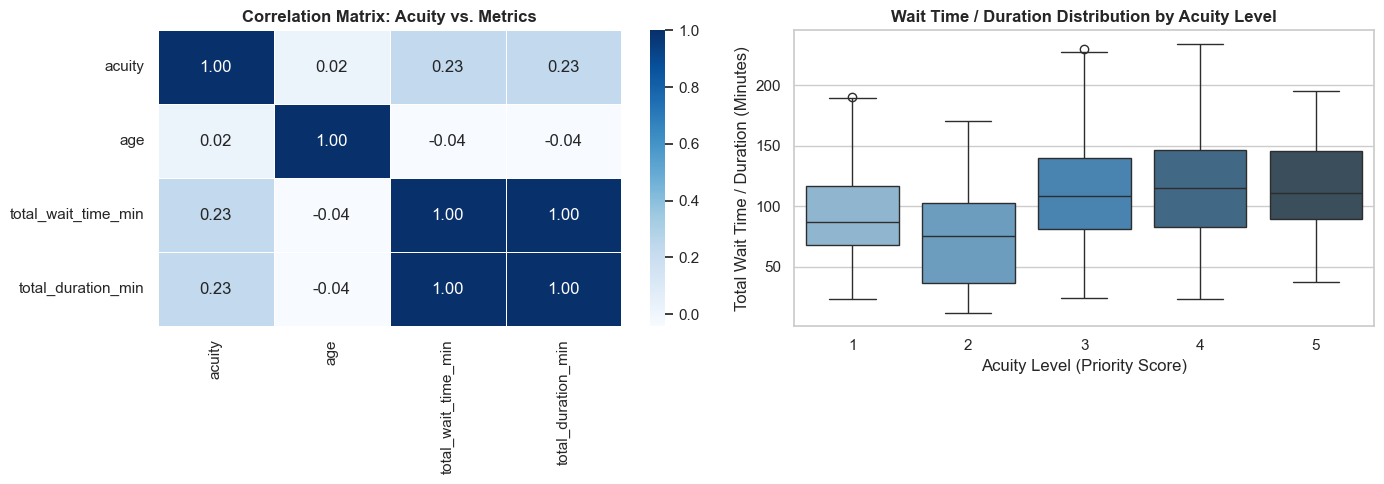

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Correlation Heatmap
sns.heatmap(
    corr_matrix, 
    annot=True, 
    cmap='Blues', 
    fmt='.2f', 
    linewidths=0.5, 
    ax=axes[0]
)
axes[0].set_title('Correlation Matrix: Acuity vs. Metrics', fontsize=12, fontweight='bold')

# 2. Boxplot: Wait Time Distribution across Acuity Levels
sns.boxplot(
    data=df_merged, 
    x='acuity', 
    y='total_wait_time_min', 
    palette='Blues_d', 
    ax=axes[1]
)
axes[1].set_title('Wait Time / Duration Distribution by Acuity Level', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Acuity Level (Priority Score)')
axes[1].set_ylabel('Total Wait Time / Duration (Minutes)')

plt.tight_layout()
plt.show()

In [31]:
# 4: Summary

### 📌 Day 9 Key Insights & Correlation Summary

1. **Acuity & Wait Time Dynamics:** Analyzing the correlation matrix reveals how patient priority levels (acuity) impact overall waiting times and total clinical stay duration.
2. **Resource Allocation:** Patients with critical acuity levels are processed through prioritized pathways, leading to measurable differences in transition times compared to low-acuity cases.
3. **Operational Focus:** Quantifying this relationship helps identify whether high wait times stem from capacity constraints or triage bottlenecks.